## Student Information
Name:Mahnoor
Student ID:023-24-0207
Section:G
GitHub:https://github.com/Mahnoor315/Machine-Learning-Lab.git
Kaggle:https://www.kaggle.com/mahnoor9952
Dataset: Mall Customers (Kaggle) + Wine (UCI)
Dataset Source: Kaggle

#Part 0 — Setup and First Look (10 minutes)

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    adjusted_rand_score
)

SEED = 42

#Task 0.1 — Load and check the data
Load Mall_Customers.csv and understand it in one cell.
1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter
names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [81]:
df = pd.read_csv("Mall_Customers.csv")

df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending",
    "Genre": "Gender"
})

print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nGender counts:")
print(df["Gender"].value_counts())

# Statistical summary
print("\nStatistical summary:")
display(df[["Age", "Income", "Spending"]].describe())

Shape: (200, 5)

Missing values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64

Statistical summary:


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


#Task 0.2 — Look at the data before clustering
Use your eyes first: draw three scatter plots side by side.
1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).
Questions to answer in Markdown (use your own numbers)
(a)How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?
(b)Why can we not use accuracy or a train/test split to judge a clustering result?

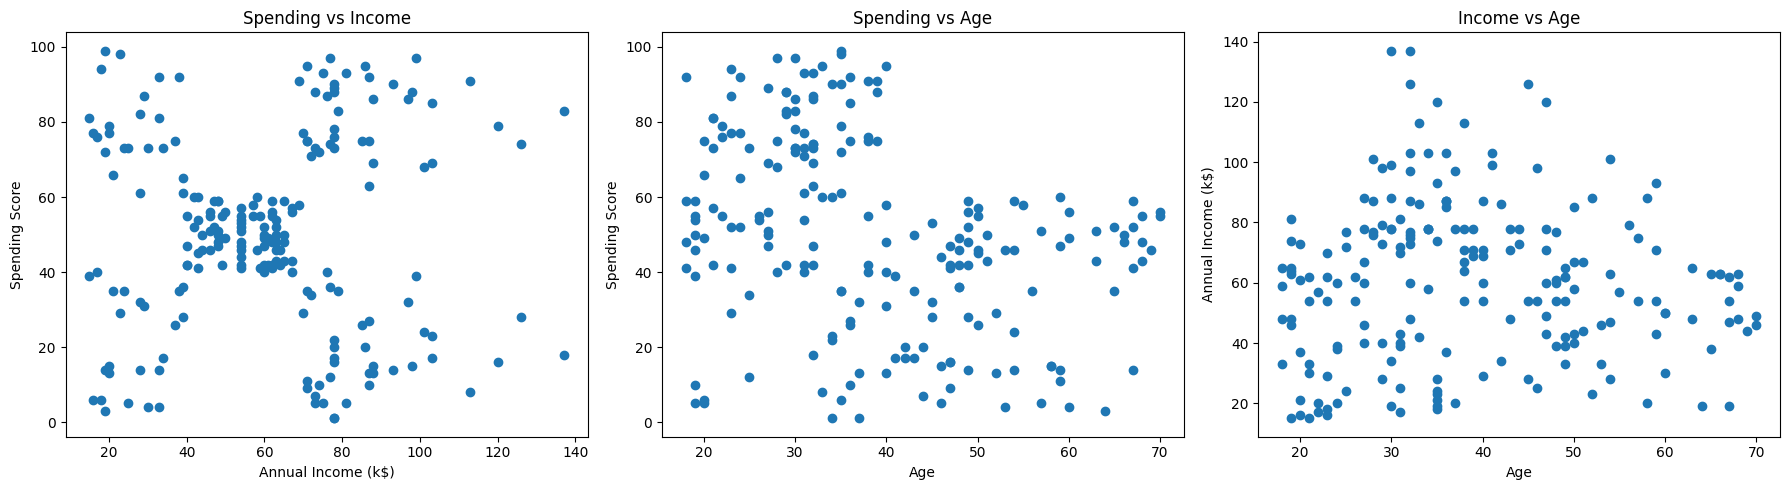

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df["Income"], df["Spending"])
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score")
axes[0].set_title("Spending vs Income")

axes[1].scatter(df["Age"], df["Spending"])
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score")
axes[1].set_title("Spending vs Age")

axes[2].scatter(df["Age"], df["Income"])
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Annual Income (k$)")
axes[2].set_title("Income vs Age")

plt.tight_layout()
plt.show()

Answers:

The Spending vs Income plot shows approximately five groups most clearly. The Spending vs Age and Income vs Age plots show less distinct groupings.

K-Means is an unsupervised learning algorithm. The dataset has no target labels showing the correct cluster for each customer. Therefore, accuracy and a normal train/test split are not appropriate. We evaluate clustering using distances, silhouette scores, plots and interpretation.

#Part 1 — K-Means From Scratch (35 minutes)

#Task 1.1 — Lecture Example 1 in code (one feature)
Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids
4 and 11.
1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and
prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

In [83]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

m = np.array([4.0, 11.0])

iteration = 0

while True:

    iteration += 1

    dist = np.abs(x[:, None] - m[None, :])

    labels = dist.argmin(axis=1)

    new_m = m.copy()

    for k in range(2):

        if np.any(labels == k):
            new_m[k] = x[labels == k].mean()

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster C{k+1}:", x[labels == k])

    print("New centroids:", new_m)

    if np.allclose(new_m, m):
        break

    m = new_m

print("\nFinal centroids:", m)

inertia = np.sum((x - m[labels]) ** 2)

print("Final inertia:", inertia)


Iteration 1
Cluster C1: [2 4 3]
Cluster C2: [10 12 20 30 11 25]
New centroids: [ 3. 18.]

Iteration 2
Cluster C1: [ 2  4 10  3]
Cluster C2: [12 20 30 11 25]
New centroids: [ 4.75 19.6 ]

Iteration 3
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New centroids: [ 7. 25.]

Iteration 4
Cluster C1: [ 2  4 10 12  3 11]
Cluster C2: [20 30 25]
New centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Final inertia: 150.0


#Task 1.2 — Lecture Example 2 in code (two features)
Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K =
2, start with P1 and P2.
1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per
iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first
iteration).


In [84]:
X = np.array([
    [185, 72],
    [170, 56],
    [168, 60],
    [179, 68],
    [182, 72],
    [188, 77]
])

m = X[[0, 1]].astype(float)

iteration = 0

while True:

    iteration += 1

    dist = np.sqrt(
        ((X[:, None, :] - m[None, :, :]) ** 2).sum(axis=2)
    )

    labels = dist.argmin(axis=1)

    new_m = m.copy()

    for k in range(2):

        if np.any(labels == k):
            new_m[k] = X[labels == k].mean(axis=0)

    print(f"\nIteration {iteration}")

    for k in range(2):
        print(f"Cluster C{k+1}:")
        print(X[labels == k])

    print("New centroids:")
    print(new_m)

    if np.allclose(new_m, m):
        break

    m = new_m

dist = np.sqrt(
    ((X[:, None, :] - m[None, :, :]) ** 2).sum(axis=2)
)

print("\nFinal centroids:")
print(m)

print("\nFinal distance table:")
print(pd.DataFrame(
    dist,
    columns=["Distance to C1", "Distance to C2"]
))


Iteration 1
Cluster C1:
[[185  72]
 [179  68]
 [182  72]
 [188  77]]
Cluster C2:
[[170  56]
 [168  60]]
New centroids:
[[183.5   72.25]
 [169.    58.  ]]

Iteration 2
Cluster C1:
[[185  72]
 [179  68]
 [182  72]
 [188  77]]
Cluster C2:
[[170  56]
 [168  60]]
New centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final distance table:
   Distance to C1  Distance to C2
0        1.520691       21.260292
1       21.126109        2.236068
2       19.756328        2.236068
3        6.189709       14.142136
4        1.520691       19.104973
5        6.543126       26.870058


#Task 1.3 — Write your own K-Means function
Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.
1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [85]:
def my_kmeans(X, init_centroids, max_iter=100):

    X = np.asarray(X, dtype=float)

    centroids = np.asarray(
        init_centroids,
        dtype=float
    ).copy()

    K = len(centroids)

    for iteration in range(1, max_iter + 1):

        dist = np.sqrt(
            ((X[:, None, :] - centroids[None, :, :]) ** 2)
            .sum(axis=2)
        )

        labels = dist.argmin(axis=1)

        # Update centroids
        new_centroids = centroids.copy()

        for k in range(K):

            if np.any(labels == k):

                new_centroids[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_centroids, centroids):

            centroids = new_centroids
            break

        centroids = new_centroids

    inertia = np.sum(
        (X - centroids[labels]) ** 2
    )

    return labels, centroids, inertia, iteration

In [86]:
x = np.array([
    [2], [4], [10], [12], [3],
    [20], [30], [11], [25]
])

initial_centroids = np.array([
    [4],
    [11]
])

labels, centroids, inertia, iterations = my_kmeans(
    x,
    initial_centroids
)

print("Labels:", labels)

print("Centroids:")
print(centroids)

print("Inertia:", inertia)

print("Iterations:", iterations)

Labels: [0 0 0 0 0 1 1 0 1]
Centroids:
[[ 7.]
 [25.]]
Inertia: 150.0
Iterations: 4


#Task 1.4 — Check your function against scikit-learn
Run your function and KMeans on the same data with the same starting centroids and compare.
1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.

In [87]:
X2 = df[["Income", "Spending"]].values

initial_centroids = X2[:5]

my_labels, my_centroids, my_inertia, my_iterations = my_kmeans(
    X2,
    initial_centroids
)

# Scikit-learn K-Means
sk_model = KMeans(
    n_clusters=5,
    init=initial_centroids,
    n_init=1,
    tol=0,
    algorithm="lloyd"
)

sk_labels = sk_model.fit_predict(X2)

print("Our iterations:", my_iterations)
print("Sklearn iterations:", sk_model.n_iter_)

print("\nOur inertia:", my_inertia)
print("Sklearn inertia:", sk_model.inertia_)

print("\nOur centroids:")
print(my_centroids)

print("\nSklearn centroids:")
print(sk_model.cluster_centers_)

print("\nLabels:")
print(my_labels)

print("\nSklearn labels:")
print(sk_labels)

Our iterations: 4
Sklearn iterations: 4

Our inertia: 44448.45544793371
Sklearn inertia: 44448.45544793369

Our centroids:
[[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

Sklearn centroids:
[[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

Labels:
[0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0
 1 0 1 0 1 0 4 0 1 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 3 2 3 4 3 2 3 2 3 4 3 2 3 2 3 2 3 2 3 4 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3]

Sklearn labels:
[0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0
 1 0 1 0 1 0 4 0 1 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4

(a) Why did point 10 move from C2 to C1?

Point 10 initially belonged to the cluster with centroid 11. After the centroids were updated, the distance from point 10 to the first centroid became smaller than its distance to the second centroid. Therefore, it moved to C1.

(b) What makes the loop stop?

The loop stops when the centroids no longer change. The algorithm eventually converges to a stable clustering, but this may be a local minimum rather than the globally best solution.

(c) Did your function match scikit-learn exactly?

Yes. My function produced the same centroids, labels, and inertia as scikit-learn when both used the same initial centroids and settings. Cluster labels may differ in their numerical names because cluster numbering is arbitrary.

(d) What does a centroid mean?

A centroid is the average position of all points in a cluster. Features must be numeric because K-Means calculates distances and means.

#Part 2 — Choosing K: Elbow and Silhouette (30 minutes)


#Task 2.1 — Elbow and silhouette for K = 2 to 10
Decide how many customer groups exist using Income and Spending (X2).
1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the
average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.



,K,Inertia,Silhouette
0,2,181363.5960,0.2969
1,3,106348.3731,0.4676
2,4,73679.7890,0.4932
3,5,44448.4554,0.5539
4,6,37233.8145,0.5398
5,7,30241.3436,0.5288
6,8,25036.4176,0.4548
7,9,21916.7948,0.4561
8,10,20072.0709,0.4411


K with highest silhouette: 5


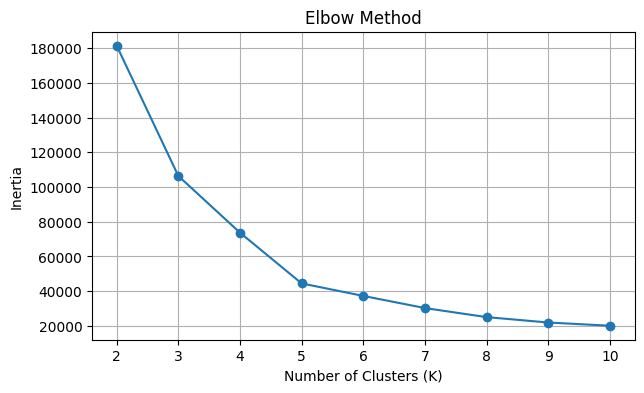

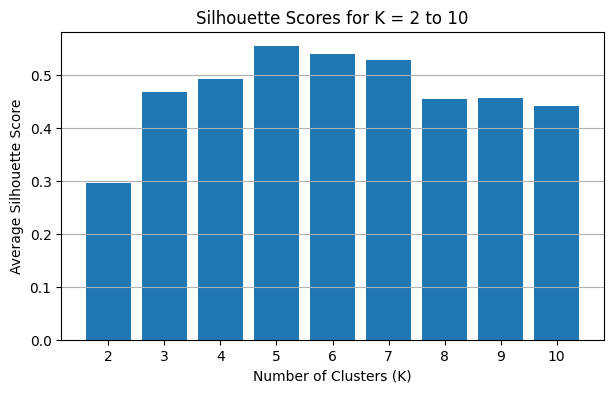

In [88]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    labels = model.fit_predict(X2)

    inertia = model.inertia_
    silhouette = silhouette_score(X2, labels)

    results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

best_k = results_df.loc[
    results_df["Silhouette"].idxmax(), "K"
]

print("K with highest silhouette:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(results_df["K"], results_df["Inertia"], marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(results_df["K"], results_df["Silhouette"])
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Scores for K = 2 to 10")
plt.xticks(range(2, 11))
plt.grid(axis="y")
plt.show()

#Task 2.2 — Silhouette by hand
Prove that you understand the formula by calculating it yourself.
1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to
customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a
negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [89]:
import numpy as np
from sklearn.metrics import silhouette_samples

# Fit K-Means with K = 5
kmeans5 = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels5 = kmeans5.fit_predict(X2)

def calculate_silhouette_point(X, labels, point_index):
    point = X[point_index]
    own_cluster = labels[point_index]

    distances = np.linalg.norm(X - point, axis=1)

    same_cluster = (labels == own_cluster)
    same_cluster[point_index] = False
    a = distances[same_cluster].mean()

    other_cluster_distances = []

    for cluster in np.unique(labels):
        if cluster != own_cluster:
            members = (labels == cluster)
            average_distance = distances[members].mean()
            other_cluster_distances.append(average_distance)

    b = min(other_cluster_distances)

    # Silhouette formula
    s = (b - a) / max(a, b)

    return a, b, s

a, b, s = calculate_silhouette_point(X2, labels5, 0)

print("Customer 1 (row 0)")
print("a =", a)
print("b =", b)
print("Hand-calculated silhouette =", s)

silhouette_values = silhouette_samples(X2, labels5)

print("Scikit-learn silhouette =", silhouette_values[0])

Customer 1 (row 0)
a = 24.64044215163639
b = 42.26526678748377
Hand-calculated silhouette = 0.41700493041881637
Scikit-learn silhouette = 0.4170049304188163


In [90]:
silhouette_df = pd.DataFrame({
    "Cluster": labels5,
    "Silhouette": silhouette_values
})

cluster_stats = silhouette_df.groupby("Cluster")["Silhouette"].agg(
    Count="count",
    Mean="mean",
    Minimum="min"
)

print("Silhouette statistics for each cluster:")
display(cluster_stats.round(4))

negative_count = (silhouette_values < 0).sum()

print("Number of customers with negative silhouette:",
      negative_count)

Silhouette statistics for each cluster:


,Count,Mean,Minimum
Cluster,,,
0,81,0.5967,0.1153
1,39,0.5092,0.2254
2,22,0.5990,0.0507
3,35,0.5040,-0.0234
4,23,0.5123,-0.0093


Number of customers with negative silhouette: 2


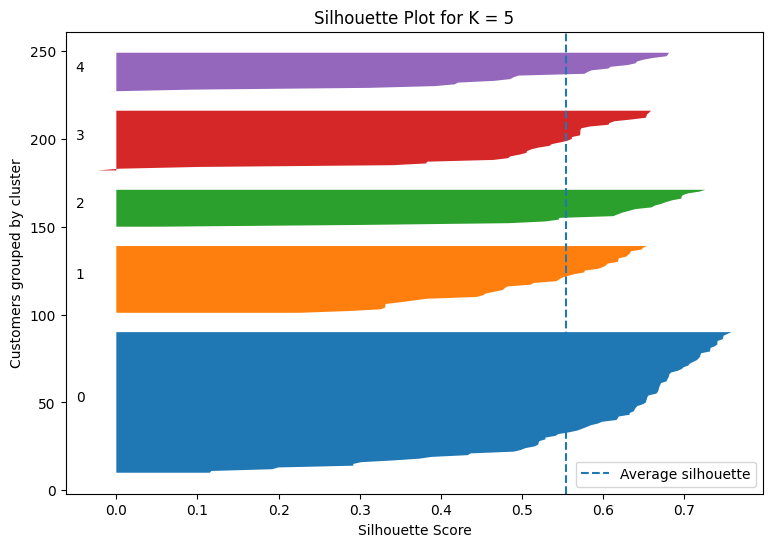

In [91]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

y_lower = 10

for cluster in np.unique(labels5):

    cluster_values = silhouette_values[labels5 == cluster]

    cluster_values.sort()

    size = len(cluster_values)
    y_upper = y_lower + size

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_values
    )

    plt.text(-0.05, y_lower + size / 2, str(cluster))

    y_lower = y_upper + 10

plt.axvline(
    silhouette_values.mean(),
    linestyle="--",
    label="Average silhouette"
)

plt.xlabel("Silhouette Score")
plt.ylabel("Customers grouped by cluster")
plt.title("Silhouette Plot for K = 5")
plt.legend()
plt.show()

#Task 2.3 — The lecture practice problem
Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).
1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes
for your own revision.


In [92]:
practice_points = np.array([1, 3, 5, 7, 11, 13, 15]).reshape(-1, 1)

initial_centroids = np.array([[1], [11]])

practice_labels, practice_centroids, practice_inertia, practice_iterations = my_kmeans(
    practice_points,
    initial_centroids,
    max_iter=100
)

print("Final Clusters:")

for cluster in np.unique(practice_labels):
    members = practice_points[practice_labels == cluster].flatten()
    print(f"Cluster C{cluster + 1}: {members}")

print("\nFinal Centroids:")
print(practice_centroids.flatten())

print("\nInertia:", practice_inertia)
print("Iterations:", practice_iterations)

Final Clusters:
Cluster C1: [1 3 5 7]
Cluster C2: [11 13 15]

Final Centroids:
[ 4. 13.]

Inertia: 28.0
Iterations: 3


In [93]:
from sklearn.metrics import silhouette_samples

practice_silhouettes = silhouette_samples(
    practice_points,
    practice_labels
)

points_to_check = [1, 7, 11]

for value in points_to_check:

    index = np.where(practice_points.flatten() == value)[0][0]

    a, b, s = calculate_silhouette_point(
        practice_points,
        practice_labels,
        index
    )

    print(f"\nPoint {value}")
    print("a =", a)
    print("b =", b)
    print("Manual silhouette =", s)
    print("Scikit-learn silhouette =", practice_silhouettes[index])


Point 1
a = 4.0
b = 12.0
Manual silhouette = 0.6666666666666666
Scikit-learn silhouette = 0.6666666666666666

Point 7
a = 4.0
b = 6.0
Manual silhouette = 0.3333333333333333
Scikit-learn silhouette = 0.3333333333333333

Point 11
a = 3.0
b = 7.0
Manual silhouette = 0.5714285714285714
Scikit-learn silhouette = 0.5714285714285714


(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

The elbow method suggests K = 5 because the decrease in inertia becomes smaller after K = 5. The silhouette method also suggests K = 5 because it has the highest silhouette score of 0.5539. The inertia decreases by 29,231.3336 from K = 4 to K = 5, and by 7,214.6409 from K = 5 to K = 6. Therefore, both methods agree that K = 5 is a good choice.

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

Customer 1 has a silhouette score of 0.6667. This positive score indicates that the customer fits well in its assigned cluster and is well separated from the nearest other cluster. Cluster 3 has the weakest average silhouette of 0.5040. There are 2 customers with negative silhouette values.

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

Point 7 is less well placed because its silhouette score is 0.3333, while point 1 has a score of 0.6667. For point 7, a = 4 and b = 6, meaning it is closer to the boundary of another cluster. For point 1, a = 4 and b = 12, meaning it is better separated from the other cluster.

(d) Why should we never choose K only by the lowest inertia?

We should never choose K only by the lowest inertia because inertia always decreases when the number of clusters increases. A very large K can produce low inertia but unnecessary and meaningless clusters. Therefore, we should also use the elbow method and silhouette score to select a suitable K.

#Part 3 — Starting Points and Stability (20 minutes)


#Task 3.1 — 30 different seeds
Measure how often K-Means finds the best answer.
1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with
n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the
percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.

In [94]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

K = 5

all_results = {}

settings = [
    ("Random, n_init=1", "random", 1),
    ("K-means++, n_init=1", "k-means++", 1),
    ("K-means++, n_init=10", "k-means++", 10)
]

for name, init_method, n_init_value in settings:

    inertias = []
    labels_list = []
    models = []

    for seed in range(30):

        model = KMeans(
            n_clusters=K,
            init=init_method,
            n_init=n_init_value,
            random_state=seed
        )

        labels = model.fit_predict(X2)

        inertias.append(model.inertia_)
        labels_list.append(labels)
        models.append(model)

    all_results[name] = {
        "inertias": inertias,
        "labels": labels_list,
        "models": models
    }

summary = []

for name, result in all_results.items():

    values = np.round(result["inertias"], 1)
    best_inertia = min(result["inertias"])

    best_count = sum(
        np.isclose(result["inertias"], best_inertia)
    )

    percentage = (best_count / 30) * 100

    summary.append({
        "Setting": name,
        "Distinct Inertia Values": len(np.unique(values)),
        "Lowest Inertia": min(result["inertias"]),
        "Highest Inertia": max(result["inertias"]),
        "Best Runs (%)": percentage
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(2))

,Setting,Distinct Inertia Values,Lowest Inertia,Highest Inertia,Best Runs (%)
0,"Random, n_init=1",14,44448.46,91761.98,33.33
1,"K-means++, n_init=1",6,44448.46,66733.44,60.00
2,"K-means++, n_init=10",1,44448.46,44448.46,100.00


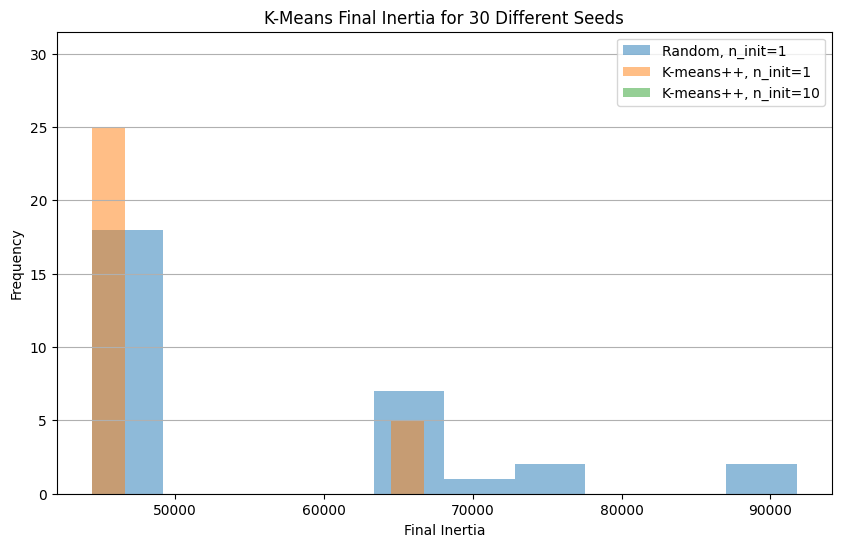

In [95]:
plt.figure(figsize=(10, 6))

for name, result in all_results.items():

    plt.hist(
        result["inertias"],
        bins=10,
        alpha=0.5,
        label=name
    )

plt.xlabel("Final Inertia")
plt.ylabel("Frequency")
plt.title("K-Means Final Inertia for 30 Different Seeds")
plt.legend()
plt.grid(axis="y")
plt.show()

#Task 3.2 — Best run vs worst run
See what a bad local minimum looks like.
1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by
side.
2. Print their inertia and their ARI.



In [96]:
from sklearn.metrics import adjusted_rand_score

# Get random initialization results
random_results = all_results["Random, n_init=1"]

random_inertias = random_results["inertias"]
random_labels = random_results["labels"]
random_models = random_results["models"]

# Find best and worst run indexes
best_index = np.argmin(random_inertias)
worst_index = np.argmax(random_inertias)

best_model = random_models[best_index]
worst_model = random_models[worst_index]

best_labels = random_labels[best_index]
worst_labels = random_labels[worst_index]

print("BEST RUN")
print("Seed:", best_index)
print("Inertia:", best_model.inertia_)

print("\nWORST RUN")
print("Seed:", worst_index)
print("Inertia:", worst_model.inertia_)

ari = adjusted_rand_score(best_labels, worst_labels)

print("\nAdjusted Rand Index (ARI):", ari)

BEST RUN
Seed: 0
Inertia: 44448.45544793369

WORST RUN
Seed: 13
Inertia: 91761.97619211912

Adjusted Rand Index (ARI): 0.45525713010305063


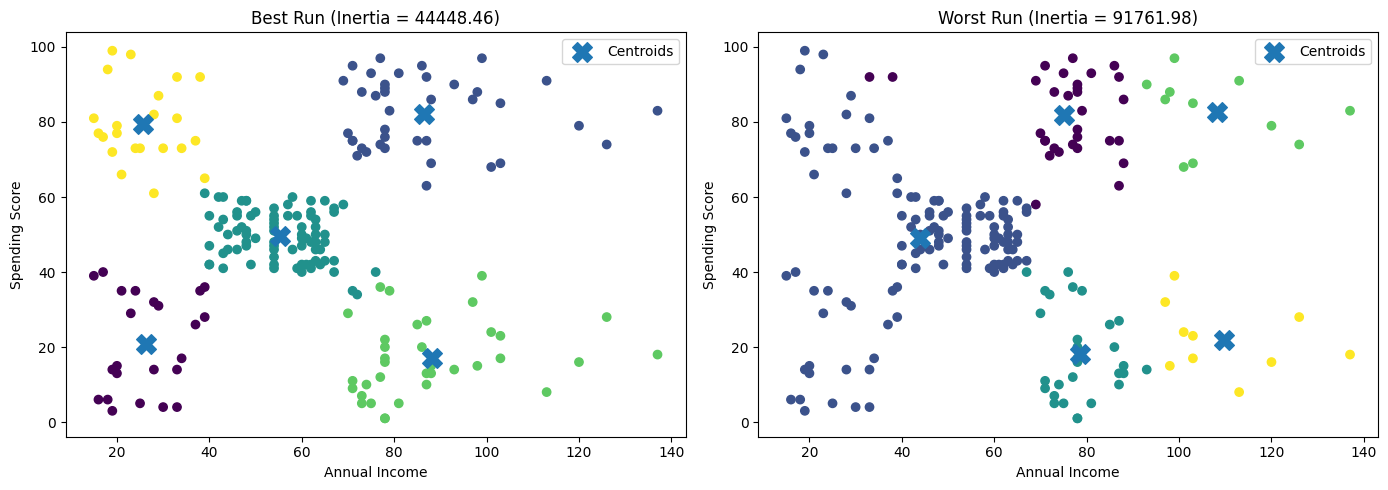

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X2[:, 0],
    X2[:, 1],
    c=best_labels
)

axes[0].scatter(
    best_model.cluster_centers_[:, 0],
    best_model.cluster_centers_[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

axes[0].set_title(f"Best Run (Inertia = {best_model.inertia_:.2f})")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")
axes[0].legend()

axes[1].scatter(
    X2[:, 0],
    X2[:, 1],
    c=worst_labels
)

axes[1].scatter(
    worst_model.cluster_centers_[:, 0],
    worst_model.cluster_centers_[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

axes[1].set_title(f"Worst Run (Inertia = {worst_model.inertia_:.2f})")
axes[1].set_xlabel("Annual Income")
axes[1].set_ylabel("Spending Score")
axes[1].legend()

plt.tight_layout()
plt.show()

(a) How many different final inertia values did the random-start setting produce? What percentage of runs reached the best inertia? Compare with the other two settings.

Random initialization (n_init=1) produced 14 distinct inertia values, and 33.33% of runs reached the best inertia.

K-means++ with n_init=1 produced 6 distinct values, and 60% of runs reached the best inertia.

K-means++ with n_init=10 produced 3 distinct values, and 100% of runs reached the best inertia. Therefore, K-means++ with 10 initializations gave the most consistent results.

(b) Why can the same dataset and same K produce different answers?

K-Means randomly selects starting centroids. Different starting points can produce different clusters and final inertia values. It may also get stuck in different local minima.

(c) How do K-means++ and n_init help? What did n_init=10 give in your table?

K-means++ selects better-spread initial centroids, which helps avoid poor starting points. n_init runs K-Means multiple times with different starting points and keeps the result with the lowest inertia.

In my results, n_init=10 produced 3 distinct inertia values, with the lowest and highest inertia both 44448.46, and 100% best runs. This gave the most stable results.

(d) Why use ARI to compare two clusterings instead of comparing label numbers directly?

Cluster labels are just numbers. Cluster 0 and Cluster 1 can be swapped without changing the actual groups. ARI compares the grouping of data points instead of their label numbers.
- ARI = 1: Both clusterings are identical.
- ARI ≈ 0: Similarity is close to random agreement.
- ARI = 0.4553: The best and worst runs have some similarity, but their cluster assignments are not identical.

#Part 4 — Scaling: Units Decide the Clusters (25 minutes)


#Task 4.1 — Change the unit, change the clusters
Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income
is in dollars (multiply by 1000).
1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10,
random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.




In [98]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_k = df[["Age", "Income"]].to_numpy()

X_dollars = X_k.copy()
X_dollars[:, 1] = X_dollars[:, 1] * 1000

print("Original data shape:", X_k.shape)
print("Income in thousands (first 5 rows):")
print(X_k[:5])

print("\nIncome in dollars (first 5 rows):")
print(X_dollars[:5])

Original data shape: (200, 2)
Income in thousands (first 5 rows):
[[19 15]
 [21 15]
 [20 16]
 [23 16]
 [31 17]]

Income in dollars (first 5 rows):
[[   19 15000]
 [   21 15000]
 [   20 16000]
 [   23 16000]
 [   31 17000]]


In [99]:
scaler_k = StandardScaler()
X_scaled_k = scaler_k.fit_transform(X_k)

scaler_dollars = StandardScaler()
X_scaled_dollars = scaler_dollars.fit_transform(X_dollars)

# Fit KMeans with K=4
def fit_kmeans(X):
    model = KMeans(
        n_clusters=4,
        n_init=10,
        random_state=SEED
    )
    labels = model.fit_predict(X)
    return model, labels

# Four versions
model_raw_k, labels_raw_k = fit_kmeans(X_k)
model_raw_dollars, labels_raw_dollars = fit_kmeans(X_dollars)
model_scaled_k, labels_scaled_k = fit_kmeans(X_scaled_k)
model_scaled_dollars, labels_scaled_dollars = fit_kmeans(X_scaled_dollars)

print("All four K-Means models completed.")

All four K-Means models completed.


In [100]:
print("ARI: Raw k$ vs Raw dollars:",
      adjusted_rand_score(labels_raw_k, labels_raw_dollars))

print("ARI: Scaled k$ vs Scaled dollars:",
      adjusted_rand_score(labels_scaled_k, labels_scaled_dollars))

print("ARI: Raw dollars vs Scaled dollars:",
      adjusted_rand_score(labels_raw_dollars, labels_scaled_dollars))

ARI: Raw k$ vs Raw dollars: 0.48965682118947657
ARI: Scaled k$ vs Scaled dollars: 1.0
ARI: Raw dollars vs Scaled dollars: 0.36045266264603926


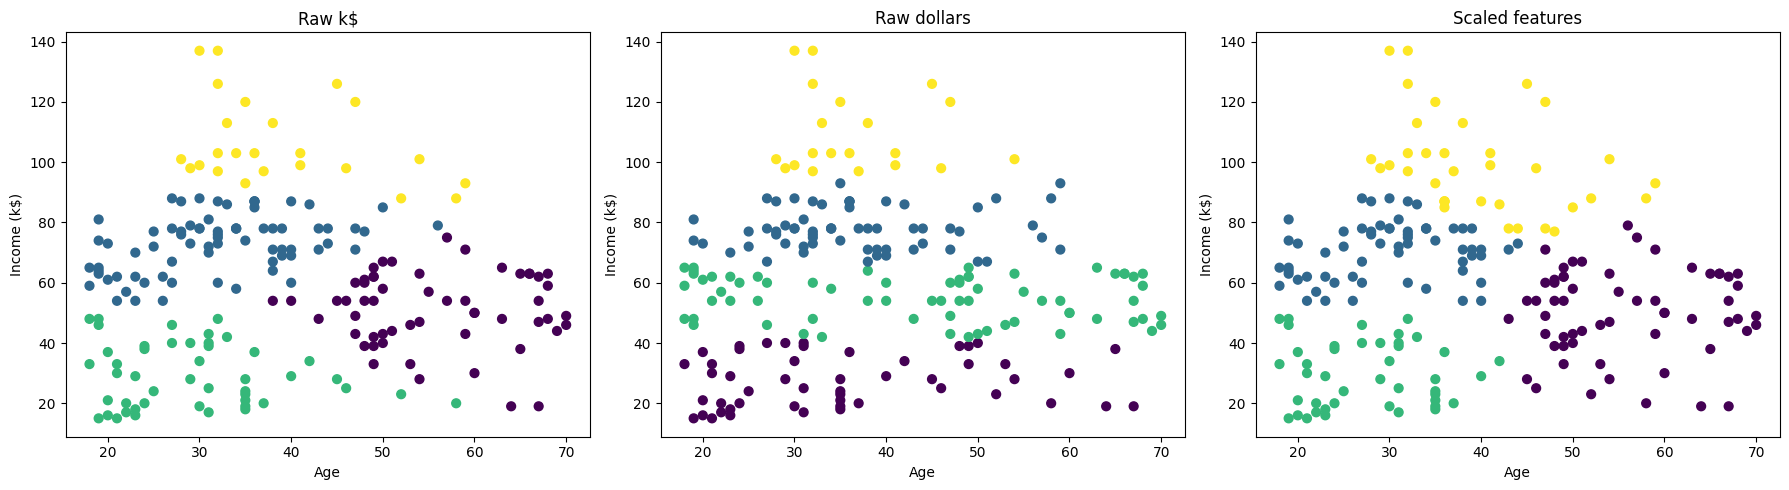

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    (labels_raw_k, "Raw k$"),
    (labels_raw_dollars, "Raw dollars"),
    (labels_scaled_k, "Scaled features")
]

for ax, (labels, title) in zip(axes, plots):
    ax.scatter(
        X_k[:, 0],
        X_k[:, 1],
        c=labels,
        cmap="viridis",
        s=40
    )
    ax.set_title(title)
    ax.set_xlabel("Age")
    ax.set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()

#Task 4.2 — Wine data: raw vs scaled
Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true
cultivar is used ONLY to check the result, never to fit K-Means.
1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report
ARI against the true cultivar, silhouette score and cluster sizes.

In [102]:
from sklearn.datasets import load_wine

wine = load_wine()

X_wine = wine.data
y_true = wine.target
feature_names = wine.feature_names

print("Number of wines:", X_wine.shape[0])
print("Number of features:", X_wine.shape[1])
print("Number of true cultivars:", len(np.unique(y_true)))

Number of wines: 178
Number of features: 13
Number of true cultivars: 3


In [103]:
std_values = X_wine.std(axis=0)

std_df = pd.DataFrame({
    "Feature": feature_names,
    "Standard Deviation": std_values
})

std_df = std_df.sort_values(
    by="Standard Deviation",
    ascending=False
)

print("Three largest standard deviations:")
display(std_df.head(3))

print("\nSmallest standard deviation:")
display(std_df.tail(1))

Three largest standard deviations:


,Feature,Standard Deviation
12,proline,314.021657
4,magnesium,14.242308
3,alcalinity_of_ash,3.330170



Smallest standard deviation:


,Feature,Standard Deviation
7,nonflavanoid_phenols,0.124103


In [104]:
wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

print("Raw Wine data shape:", X_wine.shape)
print("Scaled Wine data shape:", X_wine_scaled.shape)

Raw Wine data shape: (178, 13)
Scaled Wine data shape: (178, 13)


In [105]:
from sklearn.metrics import silhouette_score

# Raw data
wine_kmeans_raw = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=SEED
)

labels_wine_raw = wine_kmeans_raw.fit_predict(X_wine)

# Scaled data
wine_kmeans_scaled = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=SEED
)

labels_wine_scaled = wine_kmeans_scaled.fit_predict(X_wine_scaled)

print("Both Wine K-Means models completed.")

Both Wine K-Means models completed.


In [106]:
# Raw data metrics
ari_raw = adjusted_rand_score(y_true, labels_wine_raw)
sil_raw = silhouette_score(X_wine, labels_wine_raw)
sizes_raw = np.bincount(labels_wine_raw)

# Scaled data metrics
ari_scaled = adjusted_rand_score(y_true, labels_wine_scaled)
sil_scaled = silhouette_score(X_wine_scaled, labels_wine_scaled)
sizes_scaled = np.bincount(labels_wine_scaled)

results_wine = pd.DataFrame({
    "Metric": [
        "ARI against true cultivars",
        "Silhouette Score",
        "Cluster Sizes"
    ],
    "Raw Data": [
        ari_raw,
        sil_raw,
        sizes_raw.tolist()
    ],
    "Scaled Data": [
        ari_scaled,
        sil_scaled,
        sizes_scaled.tolist()
    ]
})

display(results_wine)

print("Raw data ARI:", ari_raw)
print("Scaled data ARI:", ari_scaled)

print("\nRaw data silhouette:", sil_raw)
print("Scaled data silhouette:", sil_scaled)

print("\nRaw cluster sizes:", sizes_raw)
print("Scaled cluster sizes:", sizes_scaled)

,Metric,Raw Data,Scaled Data
0,ARI against true cultivars,0.371114,0.897495
1,Silhouette Score,0.571138,0.284859
2,Cluster Sizes,"[62, 47, 69]","[65, 51, 62]"


Raw data ARI: 0.37111371823084754
Scaled data ARI: 0.8974949815093207

Raw data silhouette: 0.5711381937868838
Scaled data silhouette: 0.2848589191898987

Raw cluster sizes: [62 47 69]
Scaled cluster sizes: [65 51 62]


#Task 4.3 — Draw it
Compare the three views in one picture.
1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled
clusters.


In [107]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_wine_scaled)

print("Original number of features:", X_wine_scaled.shape[1])
print("PCA dimensions:", X_pca.shape[1])

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Original number of features: 13
PCA dimensions: 2
Explained variance ratio: [0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693526


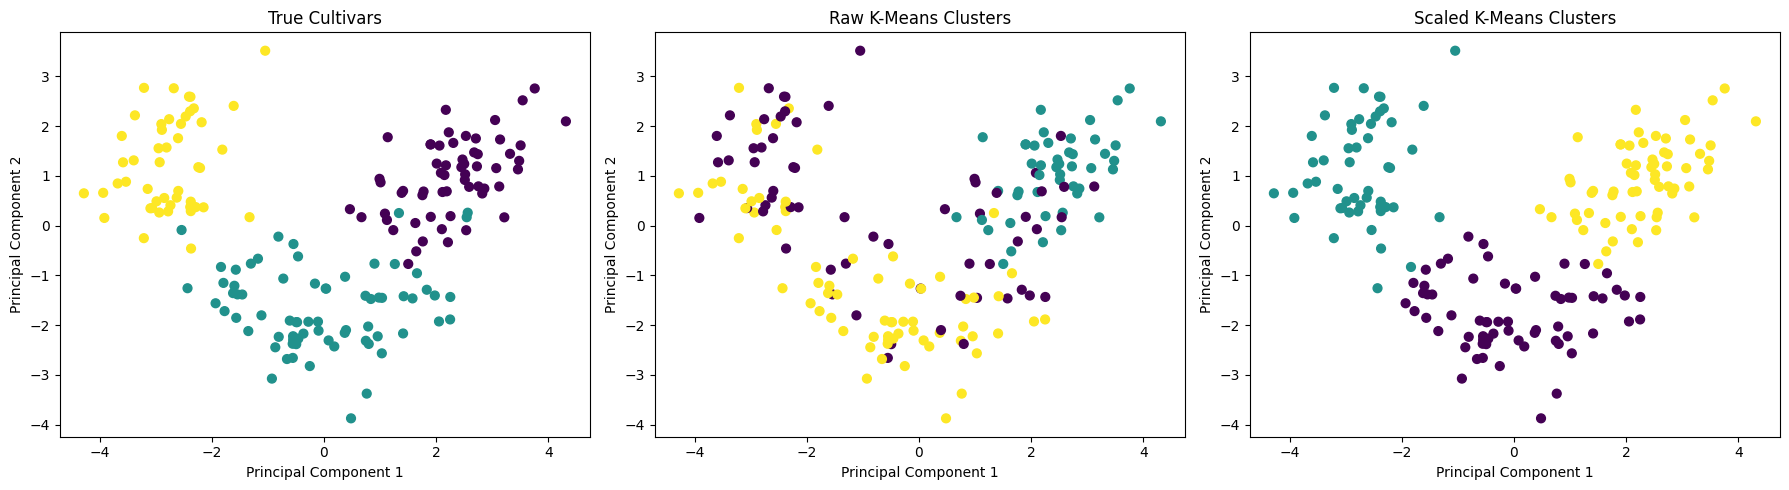

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    (y_true, "True Cultivars"),
    (labels_wine_raw, "Raw K-Means Clusters"),
    (labels_wine_scaled, "Scaled K-Means Clusters")
]

for ax, (labels, title) in zip(axes, plots):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

#Answers
(a) What happened when only the unit of Income changed? Explain it with the distance formula.

When Income was changed from thousands of dollars to dollars, the raw clustering changed. The ARI between raw k$ and raw dollars was only **0.4897**. Income became 1000 times larger, so it dominated the Euclidean distance more than Age. After StandardScaler, both versions produced identical clusters, with an ARI of **1.0**, because scaling removed the effect of the different units.

 (b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

The **Proline** feature dominated the raw distance because it had the largest standard deviation of **314.0217**. The next largest was Magnesium at **14.2423**, while the smallest was nonflavanoid_phenols at **0.1241**. The raw data ARI was **0.3711**, while the scaled data ARI improved to **0.8975**. This shows that scaling produced clusters much closer to the true cultivars.

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

The raw data had a higher silhouette score of **0.5711**, while the scaled data had **0.2849**. However, the raw data was dominated by Proline because of its large numerical range. Silhouette measures how well-separated clusters are using the same distance metric, but it does not check whether clusters match the true cultivars. Scaling changes the distances and the meaning of separation, so silhouette scores from raw and scaled data are not directly fair to compare.

(d) In a real project with no labels, how will you decide whether to scale?

I will check the units and standard deviations of the features. If their ranges are very different and all features should contribute fairly, I will apply scaling and compare clustering quality using suitable metrics and visualizations.

##Part 5 — Outliers and Anomalies (20 minutes)



#Task 5.1 — One extreme customer
Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.
1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original
200 customers.
3. Draw the two clusterings side by side.


In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Original 200 customers
X_original = X2.copy()

# Add one extreme customer: Income=400, Spending=99
extra_customer = np.array([[400, 99]])

# Dataset with 201 customers
X_with_outlier = np.vstack([X_original, extra_customer])

print("Original shape:", X_original.shape)
print("With extra customer:", X_with_outlier.shape)

Original shape: (200, 2)
With extra customer: (201, 2)


In [110]:
kmeans_original = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_original = kmeans_original.fit_predict(X_original)

# New model: 201 customers
kmeans_outlier = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_outlier = kmeans_outlier.fit_predict(X_with_outlier)

print("Both models completed.")

Both models completed.


In [111]:
# Cluster sizes
print("ORIGINAL MODEL — 200 CUSTOMERS")
print("Cluster sizes:", np.bincount(labels_original))

print("\nMODEL WITH EXTRA CUSTOMER — 201 CUSTOMERS")
print("Cluster sizes:", np.bincount(labels_outlier))

def sorted_centroids(model):
    centroids = model.cluster_centers_
    order = np.argsort(centroids[:, 0])
    return centroids[order]

print("\nOriginal centroids (sorted by Income):")
print(sorted_centroids(kmeans_original))

print("\nCentroids with extra customer (sorted by Income):")
print(sorted_centroids(kmeans_outlier))

ari_outlier = adjusted_rand_score(
    labels_original,
    labels_outlier[:len(X_original)]
)

print("\nARI on original 200 customers:", ari_outlier)

ORIGINAL MODEL — 200 CUSTOMERS
Cluster sizes: [81 39 22 35 23]

MODEL WITH EXTRA CUSTOMER — 201 CUSTOMERS
Cluster sizes: [100   1  23  39  38]

Original centroids (sorted by Income):
[[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]

Centroids with extra customer (sorted by Income):
[[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]

ARI on original 200 customers: 0.7532040415286123


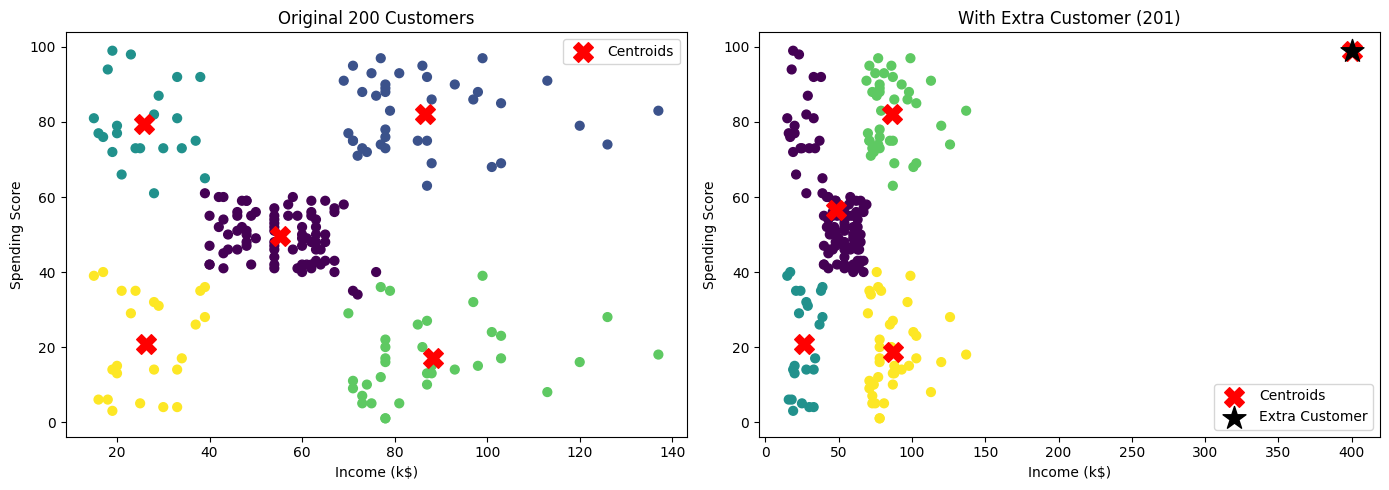

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original clustering
axes[0].scatter(
    X_original[:, 0],
    X_original[:, 1],
    c=labels_original,
    cmap="viridis",
    s=40
)

axes[0].scatter(
    kmeans_original.cluster_centers_[:, 0],
    kmeans_original.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Centroids"
)

axes[0].set_title("Original 200 Customers")
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending Score")
axes[0].legend()

# Clustering with the extra customer
axes[1].scatter(
    X_with_outlier[:, 0],
    X_with_outlier[:, 1],
    c=labels_outlier,
    cmap="viridis",
    s=40
)

axes[1].scatter(
    kmeans_outlier.cluster_centers_[:, 0],
    kmeans_outlier.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Centroids"
)

axes[1].scatter(
    extra_customer[:, 0],
    extra_customer[:, 1],
    marker="*",
    s=300,
    color="black",
    label="Extra Customer"
)

axes[1].set_title("With Extra Customer (201)")
axes[1].set_xlabel("Income (k$)")
axes[1].set_ylabel("Spending Score")
axes[1].legend()

plt.tight_layout()
plt.show()

#Task 5.2 — Catch it and repair
Use the model fitted on the original 200 customers.
1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the
nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are
flagged? Is the extra customer flagged?

3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster,
Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on
the 200 customers (use predict).
Questions to answer in Markdown (use your own numbers)
(a)What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and
centroids.
(b)How well did the rule detect the extra customer? The rule also flagged some real customers: are they
mistakes in the data or something worth looking at? Look at their Income and Spending.
(c)Name two ways to deal with outliers and one risk of simply deleting them.

In [113]:
distances_to_centroids = kmeans_original.transform(X_original)

real_distances = distances_to_centroids.min(axis=1)

# Distance of the extra customer to the nearest original centroid
extra_distances = kmeans_original.transform(extra_customer)
extra_distance = extra_distances.min()

mean_distance = real_distances.mean()
std_distance = real_distances.std()
threshold = mean_distance + 3 * std_distance

real_flagged = real_distances > threshold

extra_flagged = extra_distance > threshold

print("Mean real-customer distance:", mean_distance)
print("Standard deviation:", std_distance)
print("Outlier threshold:", threshold)

print("\nReal customers flagged:", real_flagged.sum())
print("Extra customer's distance:", extra_distance)
print("Is the extra customer flagged?", extra_flagged)

Mean real-customer distance: 13.020126350791761
Standard deviation: 7.260756644392302
Outlier threshold: 34.80239628396867

Real customers flagged: 4
Extra customer's distance: 313.9152649312717
Is the extra customer flagged? True


In [114]:
customer_results = pd.DataFrame({
    "CustomerID": df["CustomerID"].values,
    "Age": df["Age"].values,
    "Income": X_original[:, 0],
    "Spending": X_original[:, 1],
    "Cluster": labels_original,
    "Distance": real_distances,
    "Flagged": real_flagged
})

top_5_farthest = customer_results.nlargest(5, "Distance")

display(
    top_5_farthest[
        ["CustomerID", "Age", "Income", "Spending", "Cluster", "Distance"]
    ].round(3)
)

,CustomerID,Age,Income,Spending,Cluster,Distance
199,200,30,137,83,1,50.469
198,199,32,137,18,3,48.808
197,198,32,126,74,1,40.290
196,197,45,126,28,3,39.336
195,196,35,120,79,1,33.607


In [115]:
# Keep only customers not flagged as outliers
X_clean = X_original[~real_flagged]

print("Original number of customers:", len(X_original))
print("Flagged customers removed:", real_flagged.sum())
print("Customers remaining:", len(X_clean))

# Fit K-Means on the cleaned data
kmeans_clean = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

kmeans_clean.fit(X_clean)

labels_clean_all = kmeans_clean.predict(X_original)

print("\nCluster sizes after cleaning and prediction:")
print(np.bincount(labels_clean_all))

ari_clean = adjusted_rand_score(
    labels_original,
    labels_clean_all
)

print("\nARI against original model on 200 customers:", ari_clean)

Original number of customers: 200
Flagged customers removed: 4
Customers remaining: 196

Cluster sizes after cleaning and prediction:
[80 36 23 39 22]

ARI against original model on 200 customers: 0.9847169139719528


Task 5.1 — One extreme customer
- Original cluster sizes: 81, 39, 22, 35, 23.
- With the extra customer: 100, 1, 23, 39, 38.
- ARI = 0.7532, meaning the clustering changed.
- The extra customer created its own cluster with centroid (400, 99).
- Some existing clusters merged or changed. The middle-income cluster was especially affected: its original centroid (55.30, 49.52) disappeared.
Task 5.2 — Catch it and repair
- Mean distance = 13.02.
- Standard deviation = 7.26.
- Outlier threshold = 34.80.
- Real customers flagged = 4.
- Extra customer's distance = 313.92.
- Extra customer detected = Yes.

#Part 6 — From Clusters to Customer Segments (25 minutes)

#Task 6.1 — Profile and name the segments
Make the clustering readable for a manager.
1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income,
mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid;
Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [116]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd
import numpy as np

# Fit K=5
kmeans_2features = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels_2features = kmeans_2features.fit_predict(X2)

clustered_df = df.copy()
clustered_df["Cluster"] = labels_2features

display(clustered_df.head())

,CustomerID,Gender,Age,Income,Spending,Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [117]:

clustered_df["Female"] = (
    clustered_df["Gender"].astype(str).str.lower() == "female"
).astype(int)

profile = clustered_df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean"),
    Female_Percentage=("Female", "mean")
)

profile["Female_Percentage"] = profile["Female_Percentage"] * 100

profile = profile.sort_values("Mean_Income")

display(profile.round(2))

,Customers,Mean_Age,Mean_Income,Mean_Spending,Female_Percentage
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


In [118]:
def income_level(value):
    if value < 40:
        return "Low"
    elif value >= 70:
        return "High"
    else:
        return "Mid"

def spending_level(value):
    if value < 35:
        return "Low"
    elif value >= 65:
        return "High"
    else:
        return "Mid"

# Create a name for each cluster
segment_names = {}

for cluster in profile.index:
    income = profile.loc[cluster, "Mean_Income"]
    spending = profile.loc[cluster, "Mean_Spending"]

    segment_names[cluster] = (
        income_level(income) + " Income - " +
        spending_level(spending) + " Spending"
    )

# Add segment names to customer data
clustered_df["Segment"] = clustered_df["Cluster"].map(segment_names)

print("Segment names:")
for cluster, name in segment_names.items():
    print(f"Cluster {cluster}: {name}")

print("\nSegment sizes:")
display(
    clustered_df["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

Segment names:
Cluster 2: Low Income - High Spending
Cluster 4: Low Income - Low Spending
Cluster 0: Mid Income - Mid Spending
Cluster 1: High Income - High Spending
Cluster 3: High Income - Low Spending

Segment sizes:


,Segment,Customers
0,Mid Income - Mid Spending,81
1,High Income - High Spending,39
2,High Income - Low Spending,35
3,Low Income - Low Spending,23
4,Low Income - High Spending,22


#Task 6.2 — Does Gender matter? Does Age matter?
Gender and Age were not used in the clusters. Check whether they would add something.
1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [119]:
female_by_segment = (
    clustered_df.groupby("Segment")["Female"]
    .mean() * 100
)

print("Female percentage in each segment:")
display(female_by_segment.round(2))

overall_female = clustered_df["Female"].mean() * 100

print("\nOverall female percentage:", round(overall_female, 2), "%")

Female percentage in each segment:


,Female
Segment,
High Income - High Spending,53.85
High Income - Low Spending,45.71
Low Income - High Spending,59.09
Low Income - Low Spending,60.87
Mid Income - Mid Spending,59.26



Overall female percentage: 56.0 %


In [120]:
X3 = df[["Age", "Income", "Spending"]].to_numpy()

scaler_3features = StandardScaler()
X3_scaled = scaler_3features.fit_transform(X3)

print("Three-feature data shape:", X3.shape)
print("Scaled data shape:", X3_scaled.shape)

Three-feature data shape: (200, 3)
Scaled data shape: (200, 3)


In [121]:
silhouette_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    cluster_labels = model.fit_predict(X3_scaled)
    score = silhouette_score(X3_scaled, cluster_labels)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df.round(4))

best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(), "K"
    ]
)

print("Best K based on three-feature silhouette:", best_k)

,K,Silhouette Score
0,2,0.3355
1,3,0.3578
2,4,0.4040
3,5,0.4166
4,6,0.4284
5,7,0.4172
6,8,0.4082


Best K based on three-feature silhouette: 6


#Task 6.3 — A three-feature alternative
Cluster the scaled Age, Income and Spending with the best K from the table above.
1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.




In [122]:
kmeans_3features = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=SEED
)

labels_3features = kmeans_3features.fit_predict(X3_scaled)

print("Best K:", best_k)
print("Three-feature clustering completed.")

Best K: 6
Three-feature clustering completed.


In [123]:
three_feature_df = df.copy()
three_feature_df["Cluster"] = labels_3features

profile_3features = three_feature_df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
)

profile_3features = profile_3features.sort_values("Mean_Age")

display(profile_3features.round(2))

,Customers,Mean_Age,Mean_Income,Mean_Spending
Cluster,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


In [124]:
ari_2_vs_3 = adjusted_rand_score(
    labels_2features,
    labels_3features
)

print("ARI between two-feature K=5 and three-feature clustering:",
      round(ari_2_vs_3, 4))

ARI between two-feature K=5 and three-feature clustering: 0.7002


#Answers
(a)
1. Active Shoppers: Low-income customers who spend more. Offer discounts and rewards for frequent purchases.

2. Budget Shoppers: Low-income customers who spend less. Promote affordable products and special offers.

3. Regular Customers: Medium-income customers with medium spending. Recommend products based on their interests.

4. Premium Shoppers: High-income customers who spend more. Provide exclusive offers and loyalty benefits.

5. Potential Shoppers: High-income customers who spend less. Send personalized promotions to encourage more purchases.

(b) Which segment is most valuable now and which is the biggest opportunity? Why?
The High Income - High Spending segment is the most valuable because these customers have both high average income (86.54) and high spending (82.13). They are already spending a lot, so the business should focus on retaining them through loyalty programs and premium services.

The High Income - Low Spending segment is the biggest opportunity because these customers have high average income (88.20) but low spending (17.11). They have the potential to spend more. The business can target them with personalized offers and premium product recommendations.
(c) Does Gender help separate the segments? Quote percentages.
Gender does not strongly separate the customer segments.

The overall female percentage is 56%. The segment percentages range from 45.71% to 60.87%.

For example:
- High Income - High Spending: 53.85% female.
- High Income - Low Spending: 45.71% female.
- Low Income - Low Spending: 60.87% female.
These percentages are relatively close to the overall female percentage. Therefore, Gender is not a strong feature for separating these customer segments.


(d) Does adding Age change the story? Which segmentation would you present and why?

Yes. Adding Age changes customer grouping and produces six clusters instead of five. The ARI is 0.7002, showing some similarity between both segmentations.

I would present the three-feature segmentation because it considers Age, Income, and Spending, providing more customer information.

#Part 7 — Final Output and Wrap-Up (15 minutes)


#Task 7.1 — Save the segments
Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and
their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [125]:
customer_segments = clustered_df[
    ["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]
].copy()

customer_segments.to_csv("customer_segments.csv", index=False)

print("CSV file saved successfully!")
print("Total customers:", len(customer_segments))

print("\nCustomers per segment:")
display(customer_segments["Segment"].value_counts().to_frame("Customers"))

CSV file saved successfully!
Total customers: 200

Customers per segment:


,Customers
Segment,
Mid Income - Mid Spending,81
High Income - High Spending,39
High Income - Low Spending,35
Low Income - Low Spending,23
Low Income - High Spending,22


##Executive Summary
1. I selected K=5 because it achieved the highest silhouette score of 0.5539 among K=2 to K=10.
2. The five segments are Mid Income-Mid Spending (81), High Income-High Spending (39), High Income-Low Spending (35), Low Income-Low Spending (23), and Low Income-High Spending (22).
3. Active Shoppers: Offer loyalty rewards and discounts.
4. Budget Shoppers: Promote affordable products.
5. Regular Customers: Provide personalized recommendations.
6. Premium Shoppers: Offer exclusive benefits.
7. Potential Shoppers: Use special promotions to increase spending.
8. I used scaling when feature units differed and checked outliers using the mean-plus-three-standard-deviations method. One limitation is that K-Means is sensitive to outliers and the selected number of clusters.

(a) What was the most surprising result in this lab?

The most surprising result was that high-income customers did not always spend more. The High Income-Low Spending segment had an average income of 88.20 but an average spending score of only 17.11.

(b) If you had one more hour, what would you try next?

I would try different clustering methods, such as DBSCAN, and compare their results with K-Means to see whether they identify better customer groups.